# Segmentation Masks

This notebook shows how to load segmentation masks, inspect foreground and background views, and apply the same transformations to an image and its mask. It uses NyalaData dataset, but the same interface works with majority of datasets.

Run the notebook from the `notebooks/` directory. If needed, install the local package with `%pip install -e ".."`.

## 1. Load the dataset and masks

Download the masks using the standard dataset preparation procedure with `masks=True`. Existing images are reused, and the dataset automatically detects prepared masks.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from PIL import Image, ImageOps

from wildlife_datasets import datasets

root = "../data/NyalaData"
datasets.NyalaData.get_data(root, masks=True)
dataset = datasets.NyalaData(root)

/Users/lukaspicek/Documents/Projects/wildlife-datasets/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DATASET NyalaData: DOWNLOADING STARTED.
You are trying to download an already downloaded dataset.
        This message may have happened to due interrupted download or extract.
        To force the download use the `force=True` keyword such as
        get_data(..., force=True) or download(..., force=True).
        
DATASET NyalaData: FINISHED.



## 2. Access an image and its mask

Each item provides an RGB PIL image through `.image` and an aligned Boolean NumPy array through `.mask`. In the mask, `True` marks the animal and `False` marks the background. If no mask is available, `.mask` returns `None`.

The example below selects an image with a mask. Use the default `img_load="full"` and `transform=None` settings. If you set `load_label=True`, unpack the result as `item, identity = dataset[i]`.


In [2]:
positions = [i for i in range(len(dataset)) if dataset.has_mask(i)]
if not positions:
    raise ValueError("No masks are available. Prepare masks before running the examples.")

item = dataset[positions[0]]
image = item.image
mask = item.mask
print(f"Image size: {image.size}; mask shape: {mask.shape}; mask type: {mask.dtype}")

Image size: (1592, 1582); mask shape: (1582, 1592); mask type: bool


## 3. Generate image views

Segmentation masks let you isolate the animal, remove it from the scene, or show its silhouette. Access these views through `.foreground`, `.background`, and `.silhouette`, or retrieve all four evaluation views with `.cfr_views`.

Removed regions use the ImageNet RGB mean `(123, 116, 103)` as a neutral fill. `.background` and `.shortcut` refer to the same view; `.silhouette` shows the animal's outline in black.


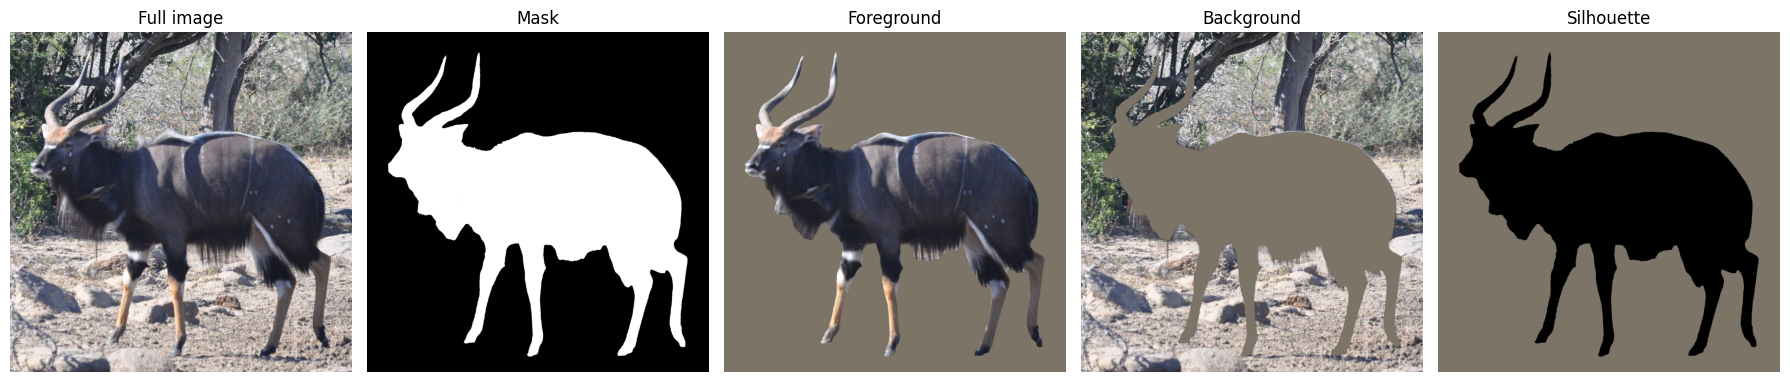

In [3]:
foreground = item.foreground
background = item.background
silhouette = item.silhouette
views = item.cfr_views

panels = {"Full image": image, "Mask": mask, "Foreground": foreground,
          "Background": background, "Silhouette": silhouette}
fig, axes = plt.subplots(1, len(panels), figsize=(18, 4))
for axis, (title, panel) in zip(axes, panels.items()):
    axis.imshow(panel, cmap="gray")
    axis.set_title(title)
    axis.axis("off")
plt.tight_layout()
plt.show()

## 4. Replace the background color

You can also use the mask to create a custom background. Here, the animal is preserved and the surrounding pixels are replaced with white.


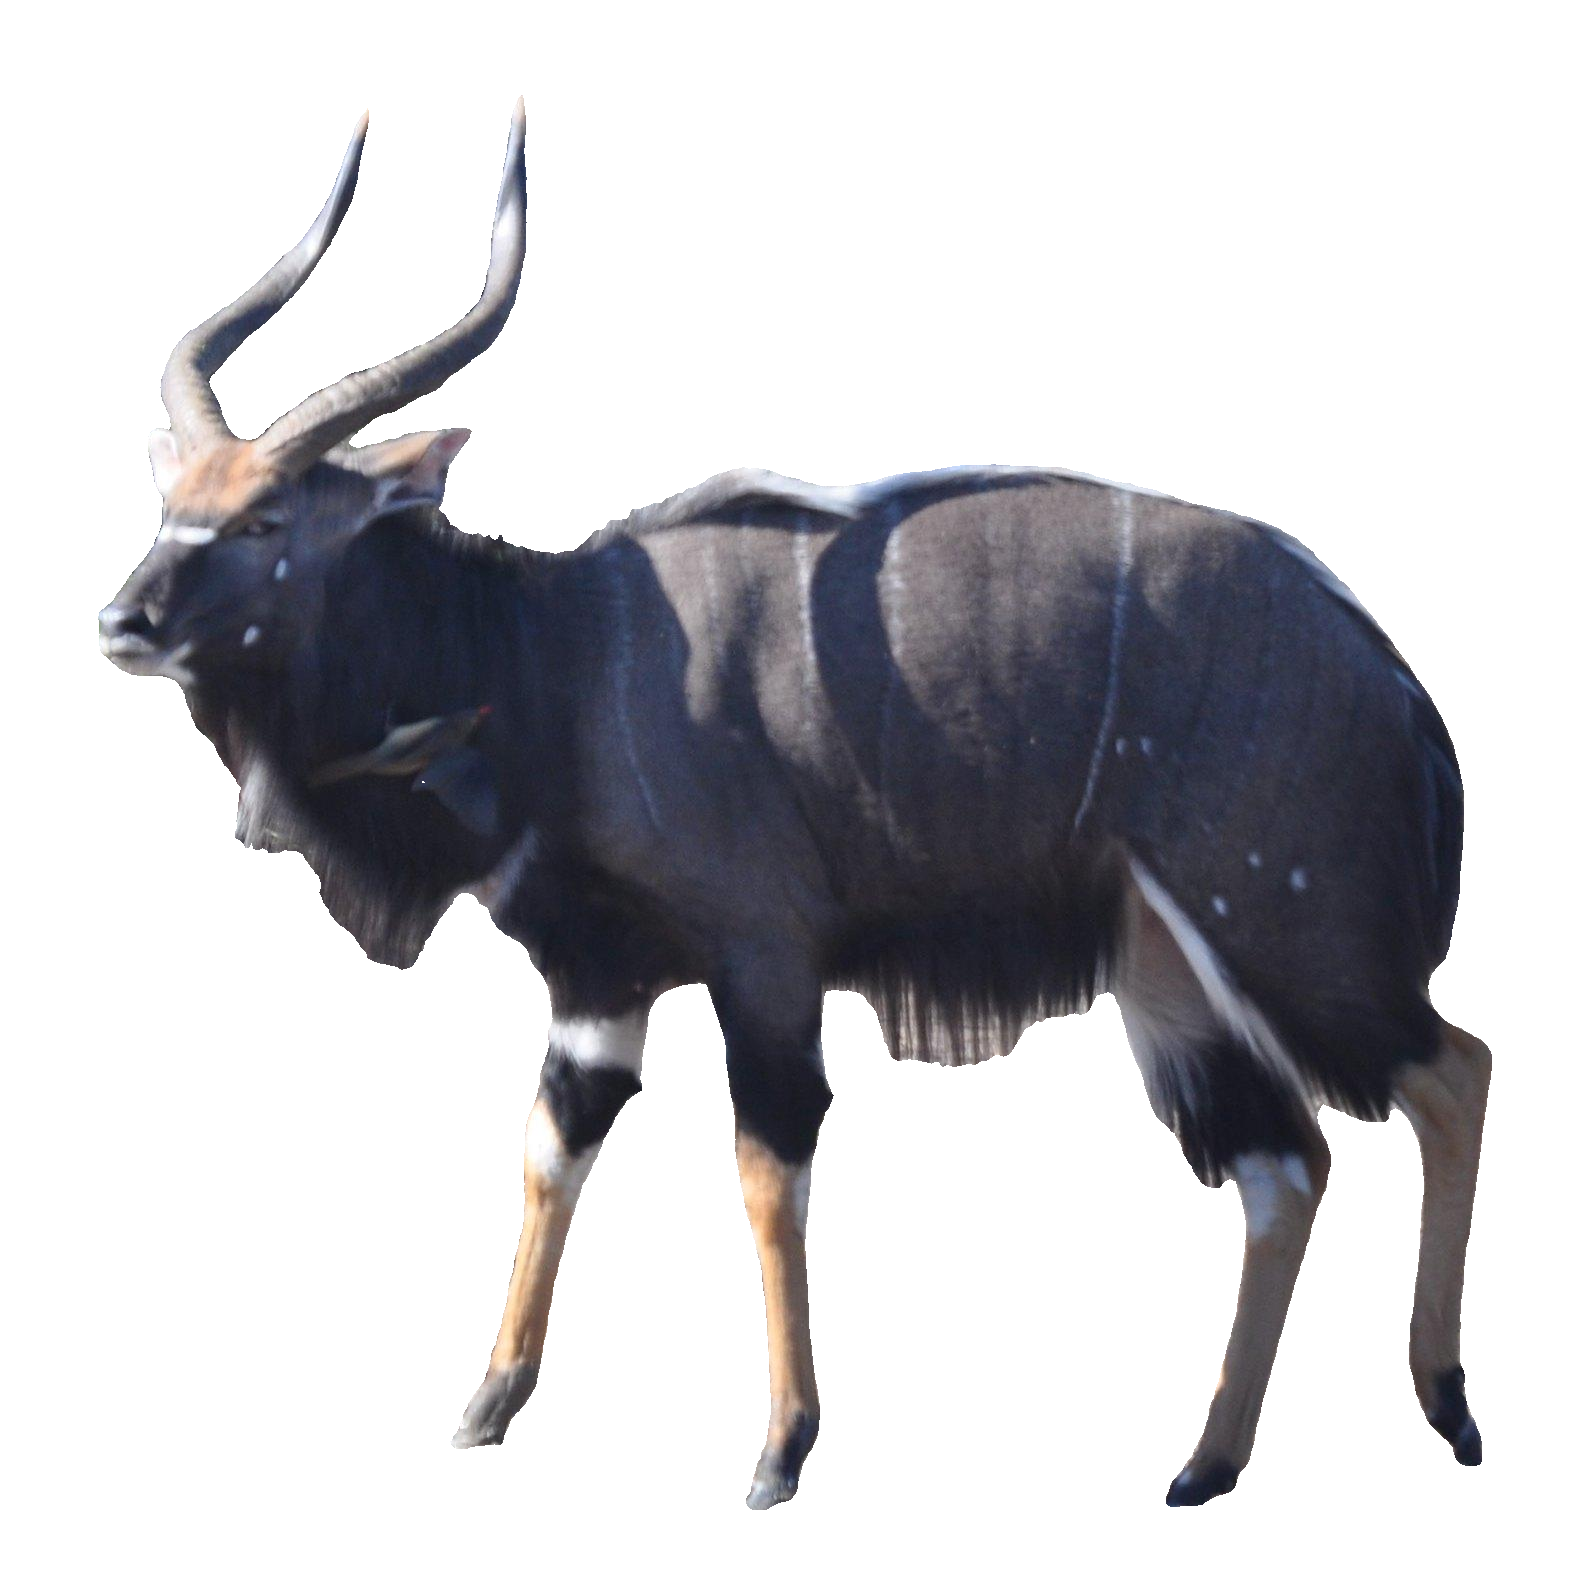

In [4]:
pixels = np.asarray(image).copy()
pixels[~mask] = [255, 255, 255]
augmented_image = Image.fromarray(pixels)
display(augmented_image)

## 5. Apply spatial transformations

Apply the same flip, crop, or rotation to both the image and its mask so they remain aligned. When resizing masks, use nearest-neighbor interpolation to preserve their binary values.


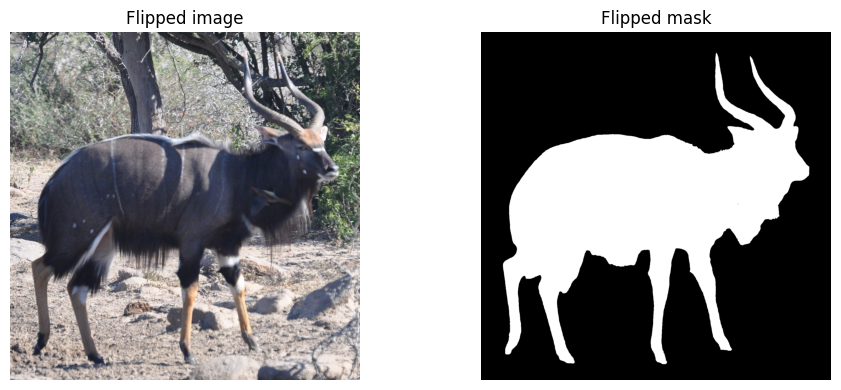

In [5]:
flipped_image = ImageOps.mirror(image)
flipped_mask = np.fliplr(mask).copy()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(flipped_image)
axes[0].set_title("Flipped image")
axes[1].imshow(flipped_mask, cmap="gray")
axes[1].set_title("Flipped mask")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

In [6]:
size = (224, 224)
resized_image = image.resize(size, Image.Resampling.BICUBIC)
resized_mask = np.asarray(
    Image.fromarray(mask).resize(size, Image.Resampling.NEAREST), dtype=bool
)
print(resized_image.size, resized_mask.shape, resized_mask.dtype)

(224, 224) (224, 224) bool


## 6. Handle missing masks

Images remain accessible even when a mask is unavailable, but generated views raise `ValueError`. You can fall back to the original image when needed:


In [7]:
sample = dataset[0]
image_or_foreground = sample.image if sample.mask is None else sample.foreground

## 7. Reconstruct the background with Moebius

Constant-color removal leaves a visible animal-shaped region. For a more natural-looking background, WildlifeDatasets supports [Moebius (ECCV 2026)](https://arxiv.org/abs/2606.19195), which reconstructs the masked area using the surrounding scene.

Install the optional dependencies with `%pip install -e "..[inpainting]"`. Create the filler once and reuse it across images. The first call loads the model and prepares it for inference, so it may take longer than later calls.


In [8]:
from time import perf_counter

from wildlife_datasets import preparation

fill = preparation.MoebiusBackgroundFill(
    num_inference_steps=10,
    mask_dilation=24,
    guidance_scale=4.5,
)


Inpainting time: 2.65 s


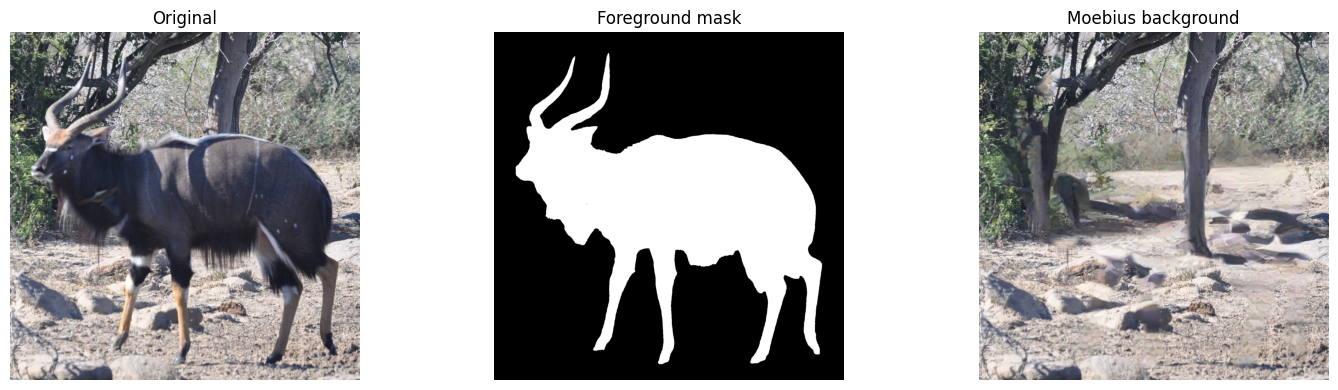

In [10]:
item = dataset[positions[0]]

start = perf_counter()
inpainted_background = fill(item, seed=42)
elapsed = perf_counter() - start
print(f"Inpainting time: {elapsed:.2f} s")

panels = {
    "Original": item.image,
    "Foreground mask": item.mask,
    "Moebius background": inpainted_background,
}
fig, axes = plt.subplots(1, len(panels), figsize=(15, 4))
for axis, (title, panel) in zip(axes, panels.items()):
    axis.imshow(panel, cmap="gray")
    axis.set_title(title)
    axis.axis("off")
plt.tight_layout()
plt.show()
